In [9]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from benchmarks.functions import forrester, FORRESTER_BOUNDS, branin, BRANIN_BOUNDS
from models.gaussian_process import GaussianProcess, SqExpKernel
from acquisition.criteria import (
    pure_exploitation,
    pure_exploration,
    lower_confidence_bound,
    probability_of_improvement,
    expected_improvement,
    propose_candidate,
)
from optimizer.bayesian_opt import BayesianOptimizer

img_dir = Path("../report/images") if Path("../report").exists() else Path("report/images")
img_dir.mkdir(parents=True, exist_ok=True)

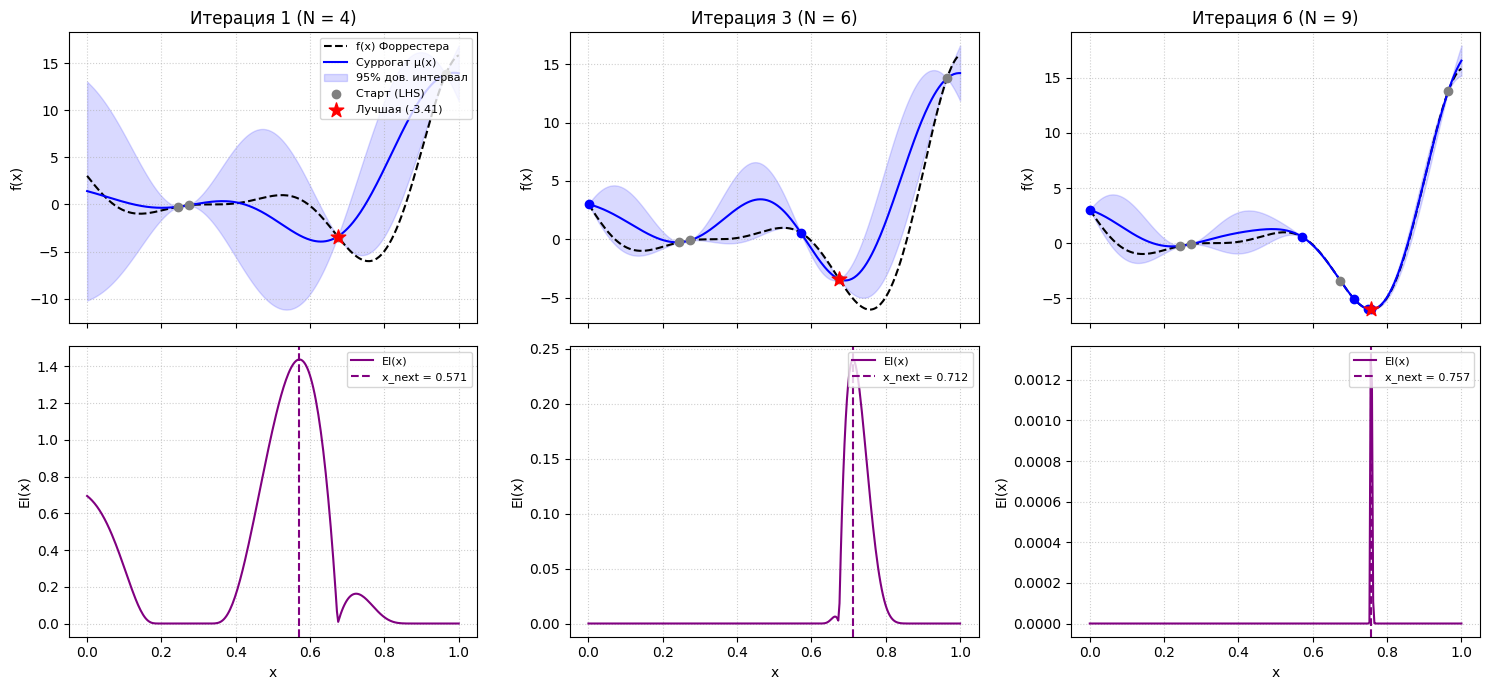

In [3]:
gp = GaussianProcess(SqExpKernel(l=0.15), noise_var=1e-6)
opt = BayesianOptimizer(forrester, FORRESTER_BOUNDS, gp, expected_improvement)
opt.initialize(n_init=4, seed=42)

X_plot = np.linspace(FORRESTER_BOUNDS[0][0], FORRESTER_BOUNDS[0][1], 300)[:, None]
y_true = forrester(X_plot)

snapshots = []
target_steps = {1, 3, 6}

for step in range(1, 7):
    x_next = propose_candidate(opt.acquisition_func, opt.surrogate, opt.bounds, opt.n_candidates, seed=42 + step)
    if step in target_steps:
        mu, std = opt.surrogate.predict(X_plot)
        ei = opt.acquisition_func(X_plot, opt.surrogate)
        snapshots.append((step, np.copy(opt.X_history), np.copy(opt.y_history), mu, std, ei, x_next[0]))
    opt.step()

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)

for col, (step, X_hist, y_hist, mu, std, ei, next_pt) in enumerate(snapshots):
    ax_top = axes[0, col]
    ax_bot = axes[1, col]

    ax_top.plot(X_plot, y_true, "k--", label="f(x) Форрестера")
    ax_top.plot(X_plot, mu, "b-", label="Суррогат μ(x)")
    ax_top.fill_between(X_plot.ravel(), mu - 1.96 * std, mu + 1.96 * std, color="b", alpha=0.15, label="95% дов. интервал")
    ax_top.scatter(X_hist[:4], y_hist[:4], color="gray", zorder=3, label="Старт (LHS)")
    if len(X_hist) > 4:
        ax_top.scatter(X_hist[4:], y_hist[4:], color="blue", zorder=4, label="Шаги BO")
    best_idx = np.argmin(y_hist)
    ax_top.scatter(X_hist[best_idx], y_hist[best_idx], color="red", marker="*", s=120, zorder=5, label=f"Лучшая ({y_hist[best_idx]:.2f})")
    ax_top.set_title(f"Итерация {step} (N = {len(X_hist)})")
    ax_top.set_ylabel("f(x)")
    ax_top.grid(True, linestyle=":", alpha=0.6)
    if col == 0:
        ax_top.legend(loc="upper right", fontsize=8)

    ax_bot.plot(X_plot, ei, color="purple", label="EI(x)")
    ax_bot.axvline(next_pt, color="purple", linestyle="--", label=f"x_next = {next_pt:.3f}")
    ax_bot.set_xlabel("x")
    ax_bot.set_ylabel("EI(x)")
    ax_bot.grid(True, linestyle=":", alpha=0.6)
    ax_bot.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.savefig(img_dir / "fig5_bo_step_evolution.png", dpi=300)
plt.show()

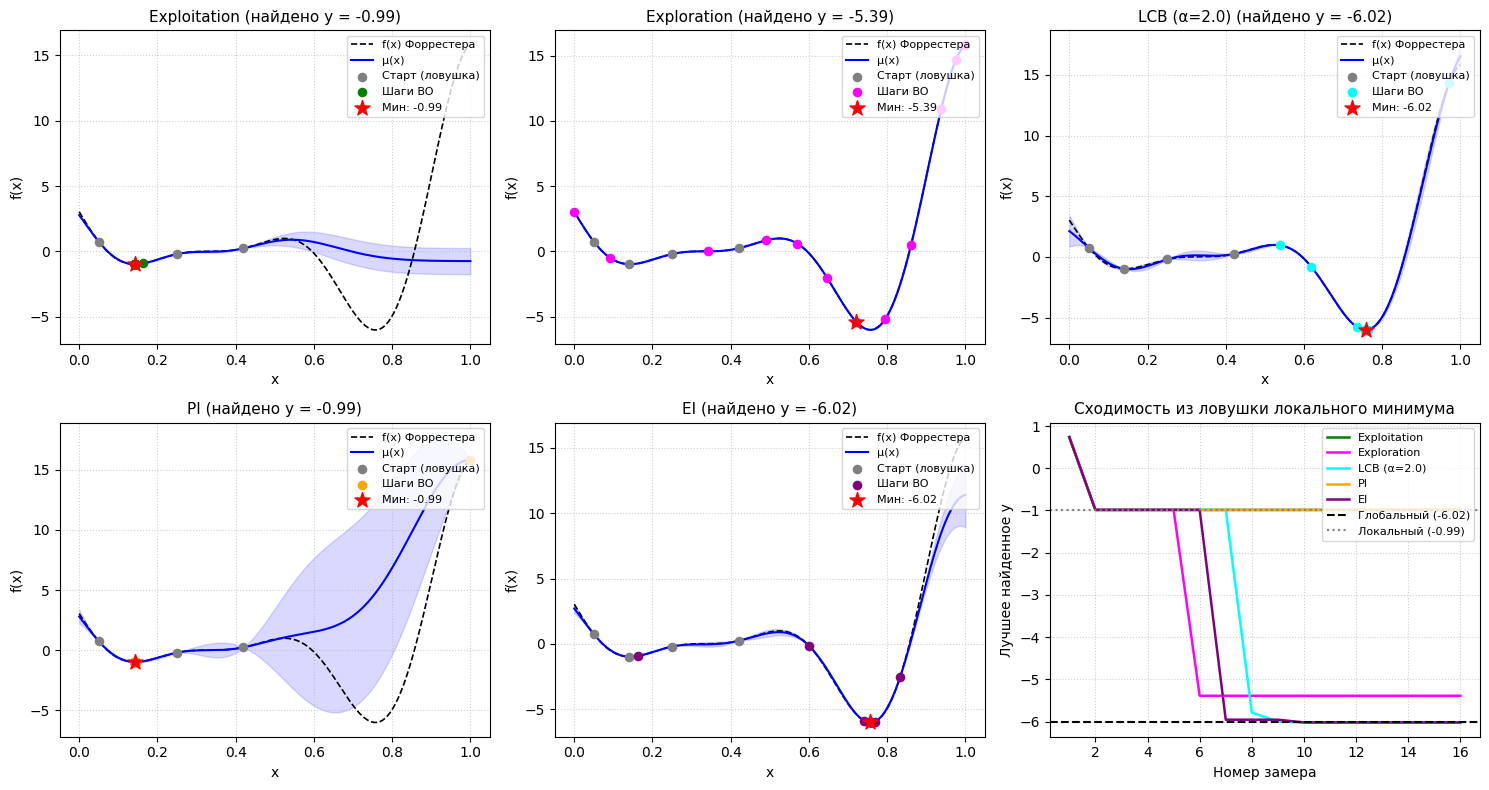

In [4]:
init_pts = np.array([[0.05], [0.14], [0.25], [0.42]])
y_init = forrester(init_pts).ravel()

criteria = {
    "Exploitation": (pure_exploitation, "green"),
    "Exploration": (pure_exploration, "magenta"),
    "LCB (α=2.0)": (lower_confidence_bound, "cyan"),
    "PI": (probability_of_improvement, "orange"),
    "EI": (expected_improvement, "purple"),
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes_flat = axes.ravel()
histories = {}

for idx, (name, (acq, color)) in enumerate(criteria.items()):
    ax = axes_flat[idx]
    gp = GaussianProcess(SqExpKernel(l=0.15), noise_var=1e-6)
    opt = BayesianOptimizer(forrester, FORRESTER_BOUNDS, gp, acq, n_candidates=1000)
    opt.X_history = np.copy(init_pts)
    opt.y_history = np.copy(y_init)
    opt.surrogate.fit(opt.X_history, opt.y_history)

    for _ in range(12):
        opt.step()

    histories[name] = (np.minimum.accumulate(opt.y_history), color)

    mu, std = opt.surrogate.predict(X_plot)
    best_idx = np.argmin(opt.y_history)
    best_x, best_y = opt.X_history[best_idx, 0], opt.y_history[best_idx]

    ax.plot(X_plot, y_true, "k--", lw=1.2, label="f(x) Форрестера")
    ax.plot(X_plot, mu, "b-", label="μ(x)")
    ax.fill_between(X_plot.ravel(), mu - 1.96 * std, mu + 1.96 * std, color="b", alpha=0.15)
    ax.scatter(opt.X_history[:4], opt.y_history[:4], color="gray", s=35, zorder=3, label="Старт (ловушка)")
    ax.scatter(opt.X_history[4:], opt.y_history[4:], color=color, s=35, zorder=4, label="Шаги BO")
    ax.scatter([best_x], [best_y], color="red", marker="*", s=130, zorder=5, label=f"Мин: {best_y:.2f}")

    ax.set_title(f"{name} (найдено y = {best_y:.2f})", fontsize=11)
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right", fontsize=8)

ax_conv = axes_flat[5]
for name, (curve, color) in histories.items():
    ax_conv.plot(range(1, len(curve) + 1), curve, label=name, color=color, lw=1.8)

ax_conv.axhline(-6.0207, color="k", linestyle="--", label="Глобальный (-6.02)")
ax_conv.axhline(-0.9863, color="gray", linestyle=":", label="Локальный (-0.99)")
ax_conv.set_xlabel("Номер замера")
ax_conv.set_ylabel("Лучшее найденное y")
ax_conv.set_title("Сходимость из ловушки локального минимума", fontsize=11)
ax_conv.grid(True, linestyle=":", alpha=0.6)
ax_conv.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.savefig(img_dir / "fig6_adversarial_trap.png", dpi=300)
plt.show()

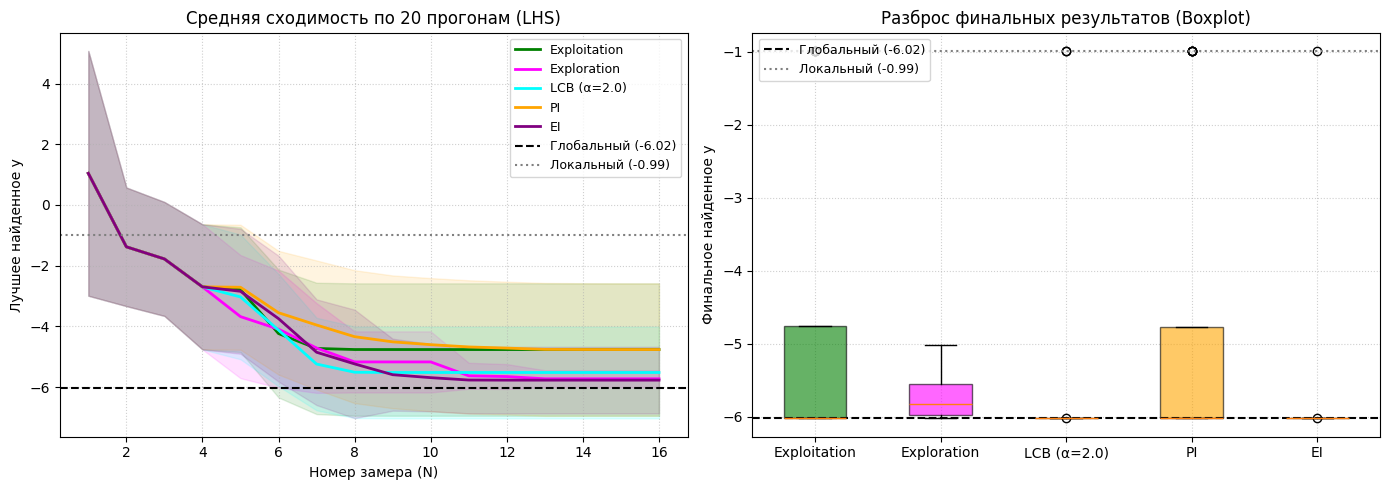

Критерий       | Среднее y  | Std y    | Мин. y   | Успех (%) 
------------------------------------------------------------
Exploitation   | -4.762     | 2.180    | -6.021   | 75.0      
Exploration    | -5.725     | 0.283    | -6.021   | 75.0      
LCB (α=2.0)    | -5.517     | 1.510    | -6.021   | 90.0      
PI             | -4.762     | 2.180    | -6.021   | 75.0      
EI             | -5.769     | 1.097    | -6.021   | 95.0      


In [5]:
n_runs = 20
n_init = 4
n_steps = 12
total_evals = n_init + n_steps

results = {name: np.zeros((n_runs, total_evals)) for name in criteria}

for run in range(n_runs):
    seed = run * 100 + 42
    for name, (acq, _) in criteria.items():
        gp = GaussianProcess(SqExpKernel(l=0.15), noise_var=1e-6)
        opt = BayesianOptimizer(forrester, FORRESTER_BOUNDS, gp, acq, n_candidates=500)
        opt.initialize(n_init=n_init, seed=seed)
        for _ in range(n_steps):
            opt.step()
        results[name][run] = np.minimum.accumulate(opt.y_history)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
steps_range = range(1, total_evals + 1)

for name, (_, color) in criteria.items():
    mean_curve = np.mean(results[name], axis=0)
    std_curve = np.std(results[name], axis=0)
    ax1.plot(steps_range, mean_curve, label=name, color=color, lw=2)
    ax1.fill_between(steps_range, mean_curve - std_curve, mean_curve + std_curve, color=color, alpha=0.12)

ax1.axhline(-6.0207, color="k", linestyle="--", label="Глобальный (-6.02)")
ax1.axhline(-0.9863, color="gray", linestyle=":", label="Локальный (-0.99)")
ax1.set_xlabel("Номер замера (N)")
ax1.set_ylabel("Лучшее найденное y")
ax1.set_title("Средняя сходимость по 20 прогонам (LHS)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper right", fontsize=9)

final_values = [results[name][:, -1] for name in criteria]
box = ax2.boxplot(final_values, patch_artist=True, tick_labels=list(criteria.keys()))
for patch, (name, (_, color)) in zip(box["boxes"], criteria.items()):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

ax2.axhline(-6.0207, color="k", linestyle="--", label="Глобальный (-6.02)")
ax2.axhline(-0.9863, color="gray", linestyle=":", label="Локальный (-0.99)")
ax2.set_ylabel("Финальное найденное y")
ax2.set_title("Разброс финальных результатов (Boxplot)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper left", fontsize=9)

plt.tight_layout()
plt.savefig(img_dir / "fig7_forrester_monte_carlo.png", dpi=300)
plt.show()

print(f"{'Критерий':<14} | {'Среднее y':<10} | {'Std y':<8} | {'Мин. y':<8} | {'Успех (%)':<10}")
print("-" * 60)
for name in criteria:
    finals = results[name][:, -1]
    success = np.mean(finals < -5.5) * 100
    print(f"{name:<14} | {np.mean(finals):<10.3f} | {np.std(finals):<8.3f} | {np.min(finals):<8.3f} | {success:<10.1f}")

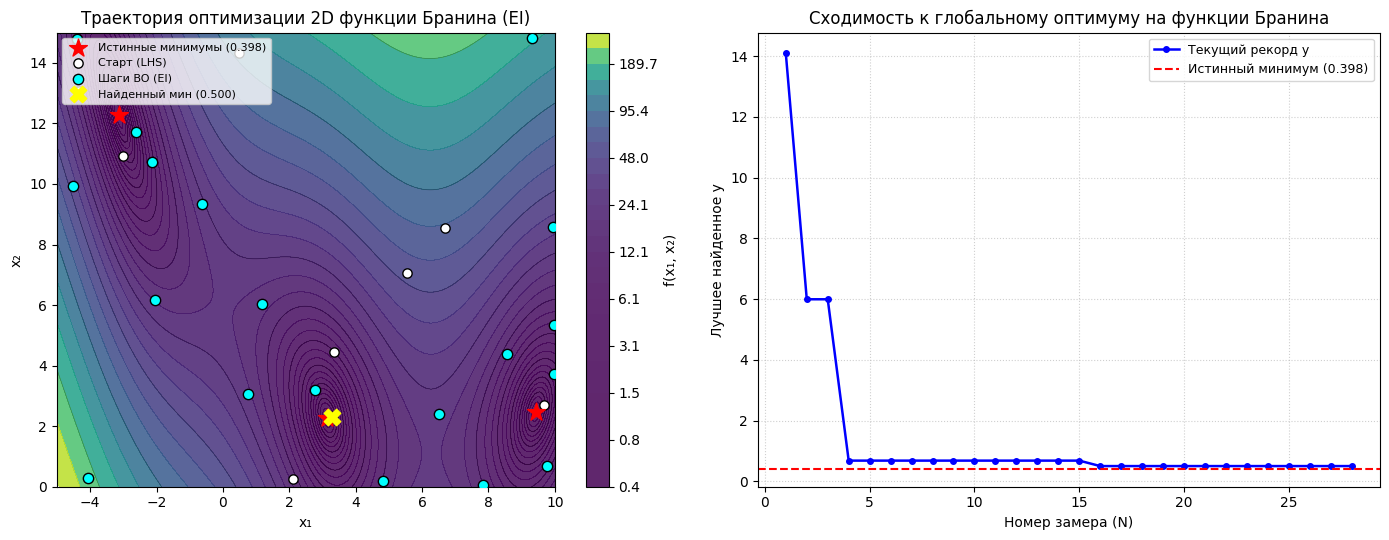

In [10]:
gp = GaussianProcess(SqExpKernel(l=2.5), noise_var=1e-6)
opt = BayesianOptimizer(branin, BRANIN_BOUNDS, gp, expected_improvement, n_candidates=1000)
opt.initialize(n_init=8, seed=42)
for _ in range(20):
    opt.step()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

x1 = np.linspace(BRANIN_BOUNDS[0][0], BRANIN_BOUNDS[0][1], 200)
x2 = np.linspace(BRANIN_BOUNDS[1][0], BRANIN_BOUNDS[1][1], 200)
X1, X2 = np.meshgrid(x1, x2)
Z = branin(np.column_stack([X1.ravel(), X2.ravel()])).reshape(X1.shape)

levels = np.logspace(np.log10(0.39), np.log10(300), 30)
cs = ax1.contourf(X1, X2, Z, levels=levels, cmap="viridis", alpha=0.85)
ax1.contour(X1, X2, Z, levels=levels[::3], colors="k", linewidths=0.5, alpha=0.3)

minima = np.array([[-np.pi, 12.275], [np.pi, 2.275], [9.42478, 2.475]])
ax1.scatter(minima[:, 0], minima[:, 1], color="red", marker="*", s=180, zorder=6, label="Истинные минимумы (0.398)")
ax1.scatter(opt.X_history[:8, 0], opt.X_history[:8, 1], color="white", edgecolors="black", s=45, zorder=4, label="Старт (LHS)")
ax1.scatter(opt.X_history[8:, 0], opt.X_history[8:, 1], color="cyan", edgecolors="black", s=55, zorder=5, label="Шаги BO (EI)")

best_idx = np.argmin(opt.y_history)
ax1.scatter([opt.X_history[best_idx, 0]], [opt.X_history[best_idx, 1]], color="yellow", marker="X", s=140, zorder=7, label=f"Найденный мин ({opt.y_history[best_idx]:.3f})")
ax1.set_xlabel("x₁")
ax1.set_ylabel("x₂")
ax1.set_title("Траектория оптимизации 2D функции Бранина (EI)")
ax1.legend(loc="upper left", fontsize=8)
fig.colorbar(cs, ax=ax1, label="f(x₁, x₂)")

running_best = np.minimum.accumulate(opt.y_history)
ax2.plot(range(1, len(running_best) + 1), running_best, "b-o", lw=1.8, ms=4, label="Текущий рекорд y")
ax2.axhline(0.397887, color="r", linestyle="--", label="Истинный минимум (0.398)")
ax2.set_xlabel("Номер замера (N)")
ax2.set_ylabel("Лучшее найденное y")
ax2.set_title("Сходимость к глобальному оптимуму на функции Бранина")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.savefig(img_dir / "fig8_branin_optimization.png", dpi=300)
plt.show()

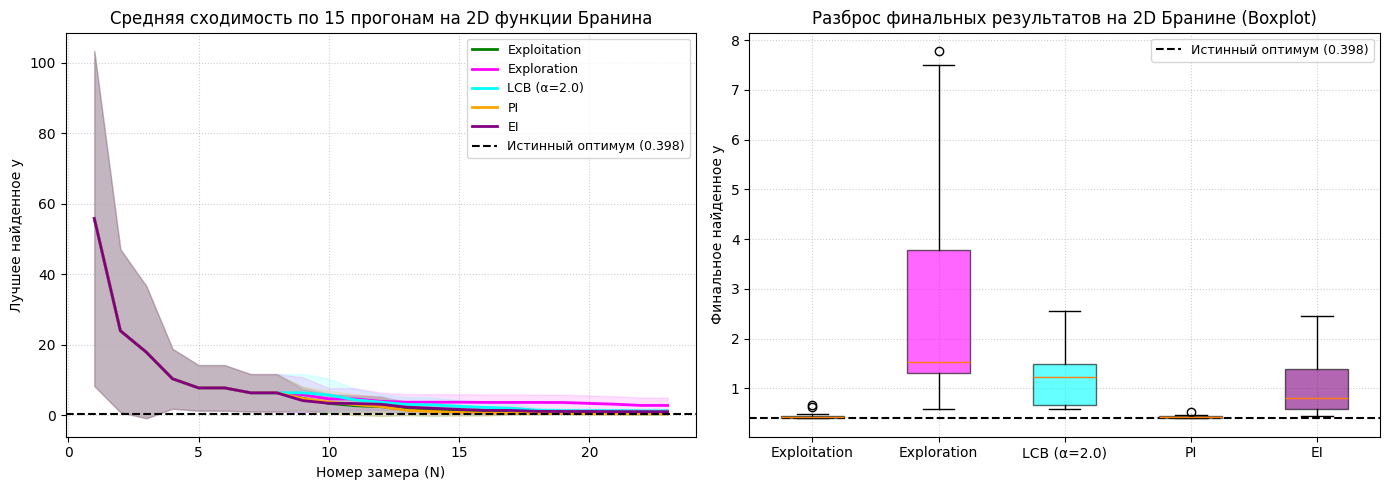

Критерий       | Среднее y  | Std y    | Мин. y   | Успех (%) 
------------------------------------------------------------
Exploitation   | 0.454      | 0.080    | 0.398    | 86.7      
Exploration    | 2.824      | 2.210    | 0.585    | 6.7       
LCB (α=2.0)    | 1.260      | 0.632    | 0.585    | 6.7       
PI             | 0.433      | 0.031    | 0.402    | 100.0     
EI             | 1.051      | 0.602    | 0.442    | 33.3      


In [11]:
n_runs_2d = 15
n_init_2d = 8
n_steps_2d = 15
total_evals_2d = n_init_2d + n_steps_2d

results_2d = {name: np.zeros((n_runs_2d, total_evals_2d)) for name in criteria}

for run in range(n_runs_2d):
    seed = run * 100 + 42
    for name, (acq, _) in criteria.items():
        gp = GaussianProcess(SqExpKernel(l=2.5), noise_var=1e-6)
        opt = BayesianOptimizer(branin, BRANIN_BOUNDS, gp, acq, n_candidates=500)
        opt.initialize(n_init=n_init_2d, seed=seed)
        for _ in range(n_steps_2d):
            opt.step()
        results_2d[name][run] = np.minimum.accumulate(opt.y_history)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
steps_range = range(1, total_evals_2d + 1)

for name, (_, color) in criteria.items():
    mean_curve = np.mean(results_2d[name], axis=0)
    std_curve = np.std(results_2d[name], axis=0)
    ax1.plot(steps_range, mean_curve, label=name, color=color, lw=2)
    ax1.fill_between(steps_range, mean_curve - std_curve, mean_curve + std_curve, color=color, alpha=0.12)

ax1.axhline(0.397887, color="k", linestyle="--", label="Истинный оптимум (0.398)")
ax1.set_xlabel("Номер замера (N)")
ax1.set_ylabel("Лучшее найденное y")
ax1.set_title("Средняя сходимость по 15 прогонам на 2D функции Бранина")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper right", fontsize=9)

final_values = [results_2d[name][:, -1] for name in criteria]
box = ax2.boxplot(final_values, patch_artist=True, tick_labels=list(criteria.keys()))
for patch, (name, (_, color)) in zip(box["boxes"], criteria.items()):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

ax2.axhline(0.397887, color="k", linestyle="--", label="Истинный оптимум (0.398)")
ax2.set_ylabel("Финальное найденное y")
ax2.set_title("Разброс финальных результатов на 2D Бранине (Boxplot)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.savefig(img_dir / "fig9_branin_monte_carlo.png", dpi=300)
plt.show()

print(f"{'Критерий':<14} | {'Среднее y':<10} | {'Std y':<8} | {'Мин. y':<8} | {'Успех (%)':<10}")
print("-" * 60)
for name in criteria:
    finals = results_2d[name][:, -1]
    success = np.mean(finals < 0.6) * 100
    print(f"{name:<14} | {np.mean(finals):<10.3f} | {np.std(finals):<8.3f} | {np.min(finals):<8.3f} | {success:<10.1f}")